# IMPORTING LIBRARIES

In [2]:
!pip install pandas numpy seaborn matplotlib

   ---------------------------------------- 0.0/9.8 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.8 MB 3.5 MB/s eta 0:00:03
   ---- ----------------------------------- 1.0/9.8 MB 2.9 MB/s eta 0:00:03
   ------ --------------------------------- 1.6/9.8 MB 2.7 MB/s eta 0:00:03
   --------- ------------------------------ 2.4/9.8 MB 2.7 MB/s eta 0:00:03
   ------------ --------------------------- 3.1/9.8 MB 2.9 MB/s eta 0:00:03
   -------------- ------------------------- 3.7/9.8 MB 2.8 MB/s eta 0:00:03
   ------------------ --------------------- 4.5/9.8 MB 3.0 MB/s eta 0:00:02
   --------------------- ------------------ 5.2/9.8 MB 3.1 MB/s eta 0:00:02
   ------------------------ --------------- 6.0/9.8 MB 3.2 MB/s eta 0:00:02
   --------------------------- ------------ 6.8/9.8 MB 3.2 MB/s eta 0:00:01
   ------------------------------- -------- 7.6/9.8 MB 3.2 MB/s eta 0:00:01
   ---------------------------------- ----- 8.4/9.8 MB 3.3 MB/s eta 0:00:01
   ----------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


# importing libraries

In [10]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# connecting to data

file_path = (r"C:\Users\samar\Downloads\call center python class\Sales and Marketing Call Center.csv")

df = pd.read_csv(file_path)




# WHO ARE THE TOP PERFORMERING AGENTS BASED ON AGENTS RATING

In [18]:
# COMBINING THE AGENTS FIRST AND LAST NAMES
df['Agent_Full_Name'] = df['Agent_First_Name'] + ' ' + df['Agent_Last_Name']
# CONVERT AGENT RATING TO  NUMERIC VALUES ... IF YOU SEE IN HOME DF THERE ARE BLANKS, PANDAS TAKES CASE OF THIS
df['Agent_Rating'] = pd.to_numeric(df['Agent_Rating'], errors= 'coerce')
# Top Agents the highest rating (5.0), use filter and display only agents with 5.0 ratings from callers removing duplicates
highest_ratings = df[df['Agent_Rating']==5.0][['Agent_Full_Name','Agent_Rating']].drop_duplicates()
highest_ratings

,Agent_Full_Name,Agent_Rating
0,Michael Page,5.0
2,Olivia Lyons,5.0
4,Ava Sandoval,5.0
6,Monique Lawrence,5.0
10,Elijah Hawkins,5.0
15,Liam Martinez,5.0
17,Samuel Smith,5.0
39,Drew Clay,5.0
48,Zoe Newman,5.0
53,Ray Mason,5.0


# What is the average call duration by agents

In [29]:
# convert agent call duration to numberic value

df['Call_Duration_Minutes'] = pd.to_numeric(df['Call_Duration_Minutes'], errors = 'coerce')

# calculate the average call duration

avg_call_duration = df.groupby('Agent_Full_Name')['Call_Duration_Minutes'].mean().round(2).reset_index()
#avg_call_duration

#sort call duration

sort_call_duration =  avg_call_duration.sort_values(by="Call_Duration_Minutes", ascending = False)
print('All Agents Average Call Duration in Minutes')
sort_call_duration

All Agents Average Call Duration in Minutes


,Agent_Full_Name,Call_Duration_Minutes
5,Michael Page,19.70
3,Katrina Williams,19.56
0,Ava Sandoval,18.64
11,Sophia Delacruz,18.62
9,Samuel Smith,16.89
7,Olivia Lyons,16.62
4,Liam Martinez,16.61
6,Monique Lawrence,16.43
10,Sarah Walter,15.91
1,Drew Clay,15.66


In [30]:
# convert agent call duration to numberic value

df['Call_Duration_Minutes'] = pd.to_numeric(df['Call_Duration_Minutes'], errors = 'coerce')

# calculate the average call duration

avg_call_duration = df.groupby('Agent_Full_Name')['Call_Duration_Minutes'].mean().round(2)
#avg_call_duration

#sort call duration

sort_call_duration =  avg_call_duration.sort_values(ascending = False)
print('All Agents Average Call Duration in Minutes')
sort_call_duration

All Agents Average Call Duration in Minutes


Agent_Full_Name
Michael Page        19.70
Katrina Williams    19.56
Ava Sandoval        18.64
Sophia Delacruz     18.62
Samuel Smith        16.89
Olivia Lyons        16.62
Liam Martinez       16.61
Monique Lawrence    16.43
Sarah Walter        15.91
Drew Clay           15.66
Elijah Hawkins      15.63
Ray Mason           15.58
Zoe Newman          15.58
Name: Call_Duration_Minutes, dtype: float64

# Which agents have the highest success rate in closing calls ?

In [57]:
# filter only successful calls by agents

successful_calls =  df[df['Call_Outcome']=='Success']
#successful_calls

#calculate the success rate per agent

success_rate = (successful_calls.groupby('Agent_Full_Name').size()/df.groupby('Agent_Full_Name').size())
#success_rate

# convert decimal to percentage string

success_rate_percentage = success_rate.apply(lambda x: f"{x : .2%}")
#success_rate_percentage

# reset index and rename column
success_rate_percentage = success_rate_percentage.reset_index(name = '%Success Rate')
#success_rate_percentage


# sort the percentage
success_rate_percentage = success_rate_percentage.sort_values(by = '%Success Rate',  ascending = False)

success_rate_percentage


,Agent_Full_Name,%Success Rate
9,Samuel Smith,90.55%
6,Monique Lawrence,90.27%
7,Olivia Lyons,90.05%
4,Liam Martinez,89.93%
5,Michael Page,89.90%
3,Katrina Williams,89.78%
1,Drew Clay,20.22%
2,Elijah Hawkins,20.21%
8,Ray Mason,20.06%
0,Ava Sandoval,19.99%


# Creating a Binary Variable for call out come from 1 to 0

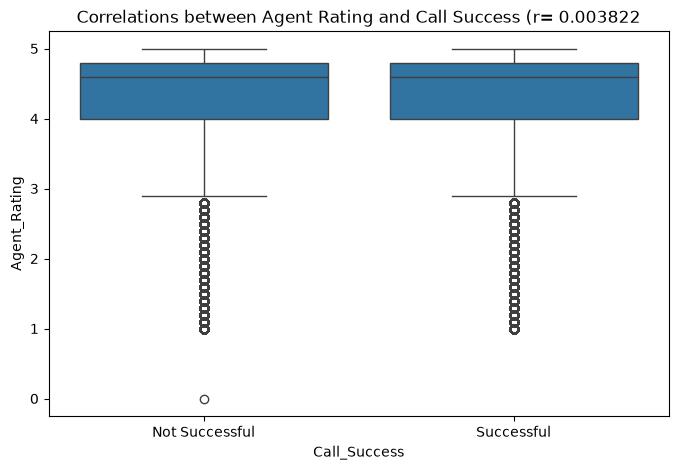

In [69]:
df['Call_Success'] = np.where(df['Call_Outcome'] == 'Success',1,0)
#df

# calculate the correlation betweeen agent rating and call success

correlation = df[['Agent_Rating','Call_Success']].corr().iloc[0,1]

# creating box plot chat 

plt.figure(figsize=(8,5))
sns.boxplot(x = df['Call_Success'], y = df['Agent_Rating'])

#customzie axis lable and title
plt.xticks(ticks = [0,1], labels = ['Not Successful','Successful'])
plt.title(f"Correlations between Agent Rating and Call Success (r={correlation: 2f}" )
plt.show()

